# Task 3 — Cuisine Classification

## Cognifyz Machine Learning Internship

### Objective

Develop a machine learning model to classify restaurants based on their cuisines using restaurant-related features.

This project treats cuisine prediction as a multi-label classification problem because a restaurant can belong to multiple cuisine categories.


## 1. Project Objective

The objective of this task is to build and evaluate a machine learning system capable of predicting the cuisines associated with restaurants.

The workflow includes:

- Data preprocessing and missing-value handling
- Feature encoding and transformation
- Multi-label target construction
- Train, validation, and test splitting
- Machine learning model development
- Precision, recall, and F1-score evaluation
- Per-cuisine performance analysis
- Class imbalance and long-tail analysis

### Project at a Glance

This project predicts the cuisines associated with restaurants as a **multi-label classification** problem, because one restaurant can have multiple cuisines.

Two One-vs-Rest models were evaluated, and **Random Forest** was selected using validation performance. The final validation-selected model and frozen-test metrics are reported in the comparative evaluation section below. The primary model uses **11 structured features** after removing redundant `Currency` information.

The main challenge is the long-tail cuisine distribution: common cuisines are learned more reliably, while many rare cuisines receive very few examples and are difficult to classify consistently.


## 2. Dataset Loading and Initial Inspection

The restaurant dataset contains restaurant identity, location, pricing, service options, ratings, votes, and cuisine information. The first stage verifies the dataset structure and data quality before modeling decisions are made.


In [1]:
# ============================================================
# COGNIFYZ ML INTERNSHIP — TASK 3
# Cuisine Classification
# Phase 1: Data Quality & Dataset Audit
# ============================================================

import pandas as pd
import numpy as np

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

# Load dataset
df = pd.read_csv("/content/Dataset .csv")

print("=" * 70)
print("COGNIFYZ ML INTERNSHIP | TASK 3")
print("RESTAURANT CUISINE CLASSIFICATION")
print("=" * 70)

print(f"\nDataset Shape       : {df.shape}")
print(f"Number of Rows      : {df.shape[0]:,}")
print(f"Number of Columns   : {df.shape[1]}")

print("\n" + "-" * 70)
print("COLUMN INFORMATION")
print("-" * 70)

df.info()

print("\n" + "-" * 70)
print("MISSING VALUES")
print("-" * 70)

missing = (
    df.isnull()
      .sum()
      .sort_values(ascending=False)
)

missing = missing[missing > 0]

if len(missing) == 0:
    print("No missing values found.")
else:
    print(missing)

print("\n" + "-" * 70)
print("DUPLICATE RECORDS")
print("-" * 70)

print(f"Duplicate rows: {df.duplicated().sum()}")

print("\n" + "-" * 70)
print("CUISINE TARGET AUDIT")
print("-" * 70)

print(f"Missing cuisine values       : {df['Cuisines'].isna().sum()}")
print(f"Unique cuisine combinations  : {df['Cuisines'].nunique():,}")

print("\nSample cuisine values:")
print(df["Cuisines"].dropna().head(10).to_string(index=False))

print("\n" + "=" * 70)
print("AUDIT COMPLETE")
print("=" * 70)

COGNIFYZ ML INTERNSHIP | TASK 3
RESTAURANT CUISINE CLASSIFICATION

Dataset Shape       : (9551, 21)
Number of Rows      : 9,551
Number of Columns   : 21

----------------------------------------------------------------------
COLUMN INFORMATION
----------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines    

### 2.1 Dataset Structure and Data Quality


The audit reports dataset shape, column information, missing values, duplicate rows, and cuisine-target completeness.


### 2.2 Feature and Target Overview


In [2]:
# ============================================================
# PHASE 2 — FEATURE CANDIDATE AUDIT
# ============================================================

print("=" * 70)
print("FEATURE CANDIDATE AUDIT")
print("=" * 70)

feature_summary = pd.DataFrame({
    "Data_Type": df.dtypes,
    "Unique_Values": df.nunique(),
    "Missing": df.isnull().sum(),
    "Missing_%": (df.isnull().mean() * 100).round(2)
})

print(feature_summary.to_string())

print("\n" + "-" * 70)
print("HIGH-CARDINALITY CATEGORICAL FEATURES")
print("-" * 70)

categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    print(f"{col:25} → {df[col].nunique():,} unique values")

FEATURE CANDIDATE AUDIT
                     Data_Type  Unique_Values  Missing  Missing_%
Restaurant ID            int64           9551        0       0.00
Restaurant Name         object           7446        0       0.00
Country Code             int64             15        0       0.00
City                    object            141        0       0.00
Address                 object           8918        0       0.00
Locality                object           1208        0       0.00
Locality Verbose        object           1265        0       0.00
Longitude              float64           8120        0       0.00
Latitude               float64           8677        0       0.00
Cuisines                object           1825        9       0.09
Average Cost for two     int64            140        0       0.00
Currency                object             12        0       0.00
Has Table booking       object              2        0       0.00
Has Online delivery     object              2       

In [3]:
# ============================================================
# NUMERICAL FEATURE SUMMARY
# ============================================================

print("=" * 70)
print("NUMERICAL FEATURE SUMMARY")
print("=" * 70)

numeric_cols = df.select_dtypes(include=np.number).columns

display(
    df[numeric_cols]
    .describe()
    .T
    .round(2)
)

NUMERICAL FEATURE SUMMARY


,count,mean,std,min,25%,50%,75%,max
Restaurant ID,9551.0,9051128.35,8791521.28,53.00,301962.50,6004089.00,18352291.50,18500652.00
Country Code,9551.0,18.37,56.75,1.00,1.00,1.00,1.00,216.00
Longitude,9551.0,64.13,41.47,-157.95,77.08,77.19,77.28,174.83
Latitude,9551.0,25.85,11.01,-41.33,28.48,28.57,28.64,55.98
Average Cost for two,9551.0,1199.21,16121.18,0.00,250.00,400.00,700.00,800000.00
Price range,9551.0,1.80,0.91,1.00,1.00,2.00,2.00,4.00
Aggregate rating,9551.0,2.67,1.52,0.00,2.50,3.20,3.70,4.90
Votes,9551.0,156.91,430.17,0.00,5.00,31.00,131.00,10934.00


## 3. Exploratory Data Analysis

EDA is used to understand cuisine frequency, restaurant-level cuisine cardinality, and the distributions that motivate the final multi-label formulation and modeling choices.


### 3.1 Cuisine Distribution


In [4]:
# ============================================================
# CUISINE DISTRIBUTION ANALYSIS
# ============================================================

cuisine_counts = (
    df["Cuisines"]
    .dropna()
    .value_counts()
)

print("=" * 70)
print("TOP 20 CUISINE COMBINATIONS")
print("=" * 70)

print(cuisine_counts.head(20))

print("\n" + "-" * 70)
print("CUISINE CLASS DISTRIBUTION")
print("-" * 70)

print(f"Total unique cuisine combinations : {len(cuisine_counts):,}")
print(f"Most common combination           : {cuisine_counts.index[0]}")
print(f"Most common combination count     : {cuisine_counts.iloc[0]:,}")
print(f"Median combination frequency      : {cuisine_counts.median():.0f}")
print(f"Minimum combination frequency     : {cuisine_counts.min():,}")
print(f"Maximum combination frequency     : {cuisine_counts.max():,}")

TOP 20 CUISINE COMBINATIONS
Cuisines
North Indian                      936
North Indian, Chinese             511
Chinese                           354
Fast Food                         354
North Indian, Mughlai             334
Cafe                              299
Bakery                            218
North Indian, Mughlai, Chinese    197
Bakery, Desserts                  170
Street Food                       149
Pizza, Fast Food                  131
Chinese, Fast Food                118
Mithai, Street Food               116
South Indian                      112
Bakery, Fast Food                 108
Chinese, North Indian             105
Mughlai                           103
Ice Cream, Desserts                83
Ice Cream                          74
North Indian, Fast Food            74
Name: count, dtype: int64

----------------------------------------------------------------------
CUISINE CLASS DISTRIBUTION
----------------------------------------------------------------------
Total u

In [5]:
# ============================================================
# PHASE 1.2 — ATOMIC CUISINE ANALYSIS
# ============================================================

# Remove missing cuisine records for target analysis
cuisine_df = df.dropna(subset=["Cuisines"]).copy()

# Convert cuisine combinations into individual cuisines
cuisine_df["Cuisine_List"] = (
    cuisine_df["Cuisines"]
    .str.split(",")
    .apply(lambda cuisines: [c.strip() for c in cuisines])
)

# Flatten all cuisine lists
all_cuisines = [
    cuisine
    for cuisine_list in cuisine_df["Cuisine_List"]
    for cuisine in cuisine_list
]

cuisine_frequency = (
    pd.Series(all_cuisines)
    .value_counts()
)

print("=" * 70)
print("ATOMIC CUISINE ANALYSIS")
print("=" * 70)

print(f"\nTotal unique individual cuisines : {len(cuisine_frequency):,}")
print(f"Total cuisine assignments        : {len(all_cuisines):,}")

print("\n" + "-" * 70)
print("TOP 30 INDIVIDUAL CUISINES")
print("-" * 70)

print(cuisine_frequency.head(30))

print("\n" + "-" * 70)
print("RARE CUISINE ANALYSIS")
print("-" * 70)

for threshold in [1, 5, 10, 20, 50, 100]:

    count = (cuisine_frequency >= threshold).sum()

    print(
        f"Cuisines appearing >= {threshold:3} times : {count:4}"
    )

ATOMIC CUISINE ANALYSIS

Total unique individual cuisines : 145
Total cuisine assignments        : 19,710

----------------------------------------------------------------------
TOP 30 INDIVIDUAL CUISINES
----------------------------------------------------------------------
North Indian     3960
Chinese          2735
Fast Food        1986
Mughlai           995
Italian           764
Bakery            745
Continental       736
Cafe              703
Desserts          653
South Indian      636
Street Food       562
American          390
Pizza             381
Mithai            380
Burger            251
Thai              234
Asian             233
Beverages         229
Ice Cream         226
Mexican           181
Biryani           177
Seafood           174
Healthy Food      150
European          148
Japanese          135
Finger Food       114
Raw Meats         114
Mediterranean     112
Salad              93
Sushi              75
Name: count, dtype: int64

-------------------------------------

### 3.2 Multi-Cuisine Restaurant Analysis


In [6]:
# ============================================================
# CUISINE CARDINALITY ANALYSIS
# ============================================================

cuisine_df["Cuisine_Count"] = cuisine_df["Cuisine_List"].apply(len)

print("=" * 70)
print("CUISINE CARDINALITY")
print("=" * 70)

print(
    cuisine_df["Cuisine_Count"]
    .value_counts()
    .sort_index()
)

print("\nAverage cuisines per restaurant:",
      round(cuisine_df["Cuisine_Count"].mean(), 2))

print("Maximum cuisines for one restaurant:",
      cuisine_df["Cuisine_Count"].max())

print("\nPercentage of restaurants with multiple cuisines:",
      round(
          (cuisine_df["Cuisine_Count"] > 1).mean() * 100,
          2
      ),
      "%"
)

CUISINE CARDINALITY
Cuisine_Count
1    3394
2    3444
3    1840
4     584
5     164
6      74
7      28
8      14
Name: count, dtype: int64

Average cuisines per restaurant: 2.07
Maximum cuisines for one restaurant: 8

Percentage of restaurants with multiple cuisines: 64.43 %


### EDA Findings

The dataset contains **145 individual cuisine labels**. Restaurants have an average of **2.07 cuisines per restaurant**, and **64.43%** of restaurants have multiple cuisine labels. This supports treating cuisine prediction as a **multi-label classification** problem.

Cuisine frequencies are highly uneven, with a small number of common cuisines and a long tail of less frequent cuisines. This imbalance is considered explicitly during target construction and evaluation.


## 4. Data Preparation and Feature Engineering

This stage defines the predictor policy, constructs the multi-label target, reduces extreme target sparsity for the primary experiment, creates multi-label stratified splits, and builds the preprocessing pipeline.


### 4.1 Feature Selection and Modeling Policy

High-cardinality identifier and text fields were excluded from the primary structured-feature model, including Restaurant ID, Restaurant Name, Address, Locality, and Locality Verbose. Restaurant Name was intentionally excluded because using it could encourage restaurant-specific memorization rather than learning generalizable structured relationships.

Rating-derived fields were treated carefully, and Cuisines was excluded from the predictors because it is the target.

`Currency` was excluded from the final primary feature set because it is largely redundant with Country Code. Removing it reduces unnecessary feature dimensions while preserving the geographic information already represented by Country Code.


In [7]:
# ============================================================
# PHASE 2.1 — FEATURE POLICY & MODELING DATASET
# ============================================================

# Remove rows with missing target labels
model_df = df.dropna(subset=["Cuisines"]).copy()

# ------------------------------------------------------------
# Feature configuration A: Core restaurant characteristics
# ------------------------------------------------------------

core_features = [
    "Country Code",
    "City",
    "Longitude",
    "Latitude",
    "Average Cost for two",
    "Has Table booking",
    "Has Online delivery",
    "Is delivering now",
    "Price range"
]

# ------------------------------------------------------------
# Feature configuration B: Extended restaurant characteristics
# ------------------------------------------------------------

extended_features = core_features + [
    "Aggregate rating",
    "Rating text",
    "Votes"
]

print("=" * 70)
print("FEATURE POLICY")
print("=" * 70)

print("\nExcluded:")
print("• Restaurant ID")
print("• Restaurant Name")
print("• Address")
print("• Locality")
print("• Locality Verbose")
print("• Cuisines (target)")
print("• Rating color")
print("• Switch to order menu")

print("\nCore feature count     :", len(core_features))
print("Extended feature count:", len(extended_features))

print("\nCore features:")
for feature in core_features:
    print("  ✓", feature)

print("\nExtended features:")
for feature in extended_features:
    print("  ✓", feature)

print("\nModeling dataset shape:", model_df.shape)

FEATURE POLICY

Excluded:
• Restaurant ID
• Restaurant Name
• Address
• Locality
• Locality Verbose
• Cuisines (target)
• Rating color
• Switch to order menu

Core feature count     : 9
Extended feature count: 12

Core features:
  ✓ Country Code
  ✓ City
  ✓ Longitude
  ✓ Latitude
  ✓ Average Cost for two
  ✓ Has Table booking
  ✓ Has Online delivery
  ✓ Is delivering now
  ✓ Price range

Extended features:
  ✓ Country Code
  ✓ City
  ✓ Longitude
  ✓ Latitude
  ✓ Average Cost for two
  ✓ Has Table booking
  ✓ Has Online delivery
  ✓ Is delivering now
  ✓ Price range
  ✓ Aggregate rating
  ✓ Rating text
  ✓ Votes

Modeling dataset shape: (9542, 21)


In [8]:
# ============================================================
# PHASE 2.2 — FEATURE QUALITY CHECK
# ============================================================

feature_quality = pd.DataFrame({
    "Unique Values": model_df[extended_features].nunique(),
    "Missing Values": model_df[extended_features].isna().sum(),
    "Data Type": model_df[extended_features].dtypes
})

feature_quality["Missing %"] = (
    feature_quality["Missing Values"]
    / len(model_df) * 100
).round(2)

display(feature_quality)

,Unique Values,Missing Values,Data Type,Missing %
Country Code,15,0,int64,0.0
City,140,0,object,0.0
Longitude,8111,0,float64,0.0
Latitude,8668,0,float64,0.0
Average Cost for two,140,0,int64,0.0
Has Table booking,2,0,object,0.0
Has Online delivery,2,0,object,0.0
Is delivering now,2,0,object,0.0
Price range,4,0,int64,0.0
Aggregate rating,33,0,float64,0.0


### 4.2 Multi-Label Target Engineering

The comma-separated cuisine field is converted into a list of cuisine labels and binarized with `MultiLabelBinarizer`. A restaurant can therefore have multiple positive target labels.


In [9]:
# ============================================================
# PHASE 3.1 — TARGET ENGINEERING
# Multi-Label Cuisine Classification
# ============================================================

from sklearn.preprocessing import MultiLabelBinarizer

target_df = model_df.copy()

# Convert cuisine strings into clean lists
target_df["Cuisine_List"] = (
    target_df["Cuisines"]
    .str.split(",")
    .apply(lambda x: [c.strip() for c in x])
)

# Remove accidental empty labels
target_df["Cuisine_List"] = target_df["Cuisine_List"].apply(
    lambda x: [c for c in x if c]
)

# Multi-label encoding
mlb = MultiLabelBinarizer()

Y = mlb.fit_transform(target_df["Cuisine_List"])

print("=" * 70)
print("MULTI-LABEL TARGET ENGINEERING")
print("=" * 70)

print(f"Restaurants             : {len(target_df):,}")
print(f"Unique cuisine labels   : {len(mlb.classes_):,}")
print(f"Target matrix shape     : {Y.shape}")

print("\nFirst 20 cuisine labels:")
print(list(mlb.classes_[:20]))

print("\nAverage labels per restaurant:",
      round(Y.sum(axis=1).mean(), 2))

MULTI-LABEL TARGET ENGINEERING
Restaurants             : 9,542
Unique cuisine labels   : 145
Target matrix shape     : (9542, 145)

First 20 cuisine labels:
['Afghani', 'African', 'American', 'Andhra', 'Arabian', 'Argentine', 'Armenian', 'Asian', 'Asian Fusion', 'Assamese', 'Australian', 'Awadhi', 'BBQ', 'Bakery', 'Bar Food', 'Belgian', 'Bengali', 'Beverages', 'Bihari', 'Biryani']

Average labels per restaurant: 2.07


In [10]:
# ============================================================
# PHASE 3.2 — LABEL SUPPORT ANALYSIS
# ============================================================

label_support = pd.Series(
    Y.sum(axis=0),
    index=mlb.classes_,
    name="Restaurant_Count"
).sort_values(ascending=False)

support_table = pd.DataFrame({
    "Restaurant_Count": label_support,
    "Percentage": (
        label_support / len(target_df) * 100
    ).round(2)
})

print("=" * 70)
print("CUISINE LABEL SUPPORT")
print("=" * 70)

display(support_table.head(30))

print("\n" + "-" * 70)

for threshold in [5, 10, 20, 50, 100]:
    print(
        f"Labels with >= {threshold:3} restaurants: "
        f"{(label_support >= threshold).sum():3}"
    )

CUISINE LABEL SUPPORT


,Restaurant_Count,Percentage
North Indian,3960,41.50
Chinese,2733,28.64
Fast Food,1986,20.81
Mughlai,994,10.42
Italian,764,8.01
Bakery,744,7.80
Continental,736,7.71
Cafe,703,7.37
Desserts,653,6.84
South Indian,636,6.67



----------------------------------------------------------------------
Labels with >=   5 restaurants: 101
Labels with >=  10 restaurants:  82
Labels with >=  20 restaurants:  57
Labels with >=  50 restaurants:  34
Labels with >= 100 restaurants:  28


### 4.3 Supported Cuisine Taxonomy

The primary experiment retains cuisine labels with at least 20 training examples. This practical support threshold reduces extreme sparsity while keeping the long-tail limitation visible in the analysis.


In [11]:
!pip install iterative-stratification -q

In [12]:
# ============================================================
# PHASE 3.3 — FINAL PRIMARY FEATURE SET
# ============================================================

primary_features = [
    "Country Code",
    "City",
    "Longitude",
    "Latitude",
    "Average Cost for two",
    "Has Table booking",
    "Has Online delivery",
    "Is delivering now",
    "Price range",
    "Aggregate rating",
    "Votes"
]

print("=" * 70)
print("PRIMARY FEATURE SET")
print("=" * 70)

for i, feature in enumerate(primary_features, 1):
    print(f"{i:2}. {feature}")

print("\nTotal features:", len(primary_features))

PRIMARY FEATURE SET
 1. Country Code
 2. City
 3. Longitude
 4. Latitude
 5. Average Cost for two
 6. Has Table booking
 7. Has Online delivery
 8. Is delivering now
 9. Price range
10. Aggregate rating
11. Votes

Total features: 11


In [13]:
# ============================================================
# PHASE 4 — MULTI-LABEL TRAIN / TEST SPLIT
# ============================================================

from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

X = target_df[primary_features].copy()
Y_full = Y.copy()

msss = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    msss.split(X, Y_full)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

Y_train_full = Y_full[train_idx]
Y_test_full = Y_full[test_idx]

print("=" * 70)
print("MULTI-LABEL TRAIN / TEST SPLIT")
print("=" * 70)

print(f"Total samples : {len(X):,}")
print(f"Training      : {len(X_train):,}")
print(f"Testing       : {len(X_test):,}")

print(f"\nTrain ratio   : {len(X_train) / len(X):.2%}")
print(f"Test ratio    : {len(X_test) / len(X):.2%}")

MULTI-LABEL TRAIN / TEST SPLIT
Total samples : 9,542
Training      : 7,621
Testing       : 1,921

Train ratio   : 79.87%
Test ratio    : 20.13%


In [14]:
# ============================================================
# PHASE 4.1 — VERIFY LABEL DISTRIBUTION
# ============================================================

train_support = pd.Series(
    Y_train_full.sum(axis=0),
    index=mlb.classes_
)

test_support = pd.Series(
    Y_test_full.sum(axis=0),
    index=mlb.classes_
)

split_check = pd.DataFrame({
    "Total": label_support,
    "Train": train_support,
    "Test": test_support
})

split_check["Train_%"] = (
    split_check["Train"] / split_check["Total"] * 100
).round(2)

split_check["Test_%"] = (
    split_check["Test"] / split_check["Total"] * 100
).round(2)

display(
    split_check
    .sort_values("Total", ascending=False)
    .head(30)
)

,Total,Train,Test,Train_%,Test_%
North Indian,3960,3168,792,80.00,20.00
Chinese,2733,2186,547,79.99,20.01
Fast Food,1986,1589,397,80.01,19.99
Mughlai,994,795,199,79.98,20.02
Italian,764,611,153,79.97,20.03
Bakery,744,595,149,79.97,20.03
Continental,736,589,147,80.03,19.97
Cafe,703,562,141,79.94,20.06
Desserts,653,522,131,79.94,20.06
South Indian,636,509,127,80.03,19.97


In [15]:
# ============================================================
# PHASE 4.2 — TRAINING-ONLY CUISINE SUPPORT
# ============================================================

# Count each cuisine only in the training set
train_support = pd.Series(
    Y_train_full.sum(axis=0),
    index=mlb.classes_
).sort_values(ascending=False)

test_support = pd.Series(
    Y_test_full.sum(axis=0),
    index=mlb.classes_
).sort_values(ascending=False)

support_analysis = pd.DataFrame({
    "Train_Count": train_support,
    "Test_Count": test_support
})

# Calculate train-only percentage
support_analysis["Train_%"] = (
    support_analysis["Train_Count"]
    / len(X_train) * 100
).round(2)

print("=" * 70)
print("TRAINING-ONLY CUISINE SUPPORT")
print("=" * 70)

print("\nCuisine labels by training support:")

for threshold in [1, 5, 10, 20, 50, 100]:
    count = (train_support >= threshold).sum()

    print(
        f"Labels with >= {threshold:3} training examples: {count:3}"
    )

print("\n" + "-" * 70)
print("RAREST TRAINING LABELS")
print("-" * 70)

display(
    support_analysis
    .sort_values("Train_Count")
    .head(20)
)

print("\n" + "-" * 70)
print("TOP TRAINING LABELS")
print("-" * 70)

display(
    support_analysis
    .sort_values("Train_Count", ascending=False)
    .head(20)
)

TRAINING-ONLY CUISINE SUPPORT

Cuisine labels by training support:
Labels with >=   1 training examples: 145
Labels with >=   5 training examples:  98
Labels with >=  10 training examples:  69
Labels with >=  20 training examples:  45
Labels with >=  50 training examples:  33
Labels with >= 100 training examples:  25

----------------------------------------------------------------------
RAREST TRAINING LABELS
----------------------------------------------------------------------


,Train_Count,Test_Count,Train_%
B�_rek,1,0,0.01
Canadian,1,0,0.01
Bubble Tea,1,0,0.01
Gourmet Fast Food,1,0,0.01
Fish and Chips,1,0,0.01
D�_ner,1,0,0.01
Durban,1,0,0.01
Cuisine Varies,1,0,0.01
Malay,1,0,0.01
Peruvian,1,0,0.01



----------------------------------------------------------------------
TOP TRAINING LABELS
----------------------------------------------------------------------


,Train_Count,Test_Count,Train_%
North Indian,3168,792,41.57
Chinese,2186,547,28.68
Fast Food,1589,397,20.85
Mughlai,795,199,10.43
Italian,611,153,8.02
Bakery,595,149,7.81
Continental,589,147,7.73
Cafe,562,141,7.37
Desserts,522,131,6.85
South Indian,509,127,6.68


In [16]:
# ============================================================
# PHASE 5 — SUPPORTED CUISINE TAXONOMY
# ============================================================

SUPPORTED_THRESHOLD = 20

supported_labels = train_support[
    train_support >= SUPPORTED_THRESHOLD
].index.tolist()

print("=" * 70)
print("SUPPORTED CUISINE TAXONOMY")
print("=" * 70)

print(f"Full cuisine taxonomy       : {len(mlb.classes_)}")
print(f"Support threshold            : {SUPPORTED_THRESHOLD}")
print(f"Supported cuisine labels     : {len(supported_labels)}")
print(f"Rare cuisine labels          : {len(mlb.classes_) - len(supported_labels)}")

print("\nSupported cuisines:")
print(supported_labels)

SUPPORTED CUISINE TAXONOMY
Full cuisine taxonomy       : 145
Support threshold            : 20
Supported cuisine labels     : 45
Rare cuisine labels          : 100

Supported cuisines:
['North Indian', 'Chinese', 'Fast Food', 'Mughlai', 'Italian', 'Bakery', 'Continental', 'Cafe', 'Desserts', 'South Indian', 'Street Food', 'American', 'Pizza', 'Mithai', 'Burger', 'Thai', 'Asian', 'Beverages', 'Ice Cream', 'Mexican', 'Biryani', 'Seafood', 'Healthy Food', 'European', 'Japanese', 'Raw Meats', 'Finger Food', 'Mediterranean', 'Salad', 'Sushi', 'Indian', 'Lebanese', 'Steak', 'Sandwich', 'Tea', 'Tibetan', 'Breakfast', 'Bar Food', 'BBQ', 'Juices', 'French', 'Bengali', 'Brazilian', 'Arabian', 'Hyderabadi']


In [17]:
# ============================================================
# PHASE 5.1 — SUPPORTED MULTI-LABEL TARGET
# ============================================================

supported_label_set = set(supported_labels)

def keep_supported_cuisines(cuisine_list):
    return [
        cuisine
        for cuisine in cuisine_list
        if cuisine in supported_label_set
    ]

target_df["Supported_Cuisines"] = (
    target_df["Cuisine_List"]
    .apply(keep_supported_cuisines)
)

# Keep restaurants having at least one supported cuisine
supported_mask = target_df["Supported_Cuisines"].apply(len) > 0

supported_df = target_df[supported_mask].copy()

# Encode supported labels
supported_mlb = MultiLabelBinarizer(
    classes=supported_labels
)

Y_supported = supported_mlb.fit_transform(
    supported_df["Supported_Cuisines"]
)

print("=" * 70)
print("SUPPORTED MULTI-LABEL TARGET")
print("=" * 70)

print(f"Original restaurants       : {len(target_df):,}")
print(f"Modeling restaurants        : {len(supported_df):,}")
print(f"Supported labels            : {len(supported_mlb.classes_)}")
print(f"Target matrix               : {Y_supported.shape}")

print(
    "\nAverage supported cuisines per restaurant:",
    round(Y_supported.sum(axis=1).mean(), 2)
)

SUPPORTED MULTI-LABEL TARGET
Original restaurants       : 9,542
Modeling restaurants        : 9,374
Supported labels            : 45
Target matrix               : (9374, 45)

Average supported cuisines per restaurant: 2.02


### 4.4 Final Train / Validation / Test Design

An 80/20 multi-label stratified train/test split is frozen for final evaluation. A further stratified split of the training portion creates the validation set used for threshold selection and model comparison. The final test set is not used for threshold tuning.


In [18]:
# ============================================================
# PHASE 5.2 — FINAL MULTI-LABEL MODEL SPLIT
# ============================================================

from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

# Final feature matrix
X_final = supported_df[primary_features].copy()

# Final target
Y_final = Y_supported.copy()

# Multi-label stratified split
final_splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx_final, test_idx_final = next(
    final_splitter.split(X_final, Y_final)
)

X_train_final = X_final.iloc[train_idx_final].copy()
X_test_final = X_final.iloc[test_idx_final].copy()

Y_train_final = Y_final[train_idx_final]
Y_test_final = Y_final[test_idx_final]

print("=" * 70)
print("FINAL MODEL TRAIN / TEST SPLIT")
print("=" * 70)

print(f"Total modeling samples : {len(X_final):,}")
print(f"Training samples       : {len(X_train_final):,}")
print(f"Testing samples        : {len(X_test_final):,}")

print(
    f"\nTrain ratio            : "
    f"{len(X_train_final) / len(X_final):.2%}"
)

print(
    f"Test ratio             : "
    f"{len(X_test_final) / len(X_final):.2%}"
)

print(f"\nFeature count          : {X_final.shape[1]}")
print(f"Target labels          : {Y_final.shape[1]}")

FINAL MODEL TRAIN / TEST SPLIT
Total modeling samples : 9,374
Training samples       : 7,506
Testing samples        : 1,868

Train ratio            : 80.07%
Test ratio             : 19.93%

Feature count          : 11
Target labels          : 45


In [19]:
# ============================================================
# PHASE 5.3 — FINAL LABEL DISTRIBUTION CHECK
# ============================================================

final_train_support = pd.Series(
    Y_train_final.sum(axis=0),
    index=supported_mlb.classes_
)

final_test_support = pd.Series(
    Y_test_final.sum(axis=0),
    index=supported_mlb.classes_
)

final_distribution = pd.DataFrame({
    "Train": final_train_support,
    "Test": final_test_support
})

final_distribution["Train_%"] = (
    final_distribution["Train"]
    / len(X_train_final) * 100
).round(2)

final_distribution["Test_%"] = (
    final_distribution["Test"]
    / len(X_test_final) * 100
).round(2)

display(
    final_distribution
    .sort_values("Train", ascending=False)
)

,Train,Test,Train_%,Test_%
North Indian,3168,792,42.21,42.40
Chinese,2186,547,29.12,29.28
Fast Food,1589,397,21.17,21.25
Mughlai,795,199,10.59,10.65
Italian,611,153,8.14,8.19
Bakery,595,149,7.93,7.98
Continental,589,147,7.85,7.87
Cafe,562,141,7.49,7.55
Desserts,522,131,6.95,7.01
South Indian,509,127,6.78,6.80


### 4.5 Numerical and Categorical Preprocessing

Highly skewed cost and vote features receive median imputation, `log1p`, and standardization. Other numerical features are median-imputed and standardized, while categorical variables are most-frequent imputed and one-hot encoded. Longitude and latitude are not log-transformed because they can contain negative values.


In [20]:
# ============================================================
# PHASE 6.1 — NUMERICAL DISTRIBUTION & SKEWNESS AUDIT
# ============================================================

from scipy.stats import skew

numeric_features = [
    "Longitude",
    "Latitude",
    "Average Cost for two",
    "Price range",
    "Aggregate rating",
    "Votes"
]

skewness_table = pd.DataFrame({
    "Mean": X_train_final[numeric_features].mean(),
    "Median": X_train_final[numeric_features].median(),
    "Std": X_train_final[numeric_features].std(),
    "Skewness": X_train_final[numeric_features].apply(
        lambda x: skew(x, bias=False)
    )
}).round(3)

print("=" * 70)
print("NUMERICAL FEATURE SKEWNESS")
print("=" * 70)

display(skewness_table)

NUMERICAL FEATURE SKEWNESS


,Mean,Median,Std,Skewness
Longitude,64.722,77.194,40.444,-2.922
Latitude,25.933,28.571,10.772,-3.164
Average Cost for two,1043.562,400.000,13999.823,39.895
Price range,1.783,2.000,0.895,0.926
Aggregate rating,2.637,3.200,1.518,-0.934
Votes,149.492,29.000,399.574,7.644


In [21]:
# ============================================================
# PHASE 6.2 — EXTREME VALUE AUDIT
# ============================================================

for col in ["Average Cost for two", "Votes"]:

    print("\n" + "=" * 70)
    print(f"{col.upper()} DISTRIBUTION")
    print("=" * 70)

    print(X_train_final[col].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2))


AVERAGE COST FOR TWO DISTRIBUTION
count      7506.00
mean       1043.56
std       13999.82
min           0.00
50%         400.00
75%         700.00
90%        1200.00
95%        1650.00
99%        3000.00
max      800000.00
Name: Average Cost for two, dtype: float64

VOTES DISTRIBUTION
count    7506.00
mean      149.49
std       399.57
min         0.00
50%        29.00
75%       125.00
90%       365.00
95%       665.00
99%      1861.85
max      7931.00
Name: Votes, dtype: float64


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    FunctionTransformer
)
from sklearn.impute import SimpleImputer
import numpy as np

# ============================================================
# 1. Define numerical and categorical features
# ============================================================

log_numeric_features = [
    "Average Cost for two",
    "Votes"
]

regular_numeric_features = [
    "Longitude",
    "Latitude",
    "Price range",
    "Aggregate rating"
]

categorical_features = [
    "Country Code",
    "City",
    "Has Table booking",
    "Has Online delivery",
    "Is delivering now"
]


# ============================================================
# 2. Pipeline for highly skewed numerical features
# ============================================================

log_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler())
])


# ============================================================
# 3. Pipeline for regular numerical features
# ============================================================

regular_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# ============================================================
# 4. Pipeline for categorical features
# ============================================================

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])


# ============================================================
# 5. Combine everything
# ============================================================

preprocessor = ColumnTransformer([
    (
        "log_numeric",
        log_numeric_pipeline,
        log_numeric_features
    ),
    (
        "regular_numeric",
        regular_numeric_pipeline,
        regular_numeric_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])


print("✅ Preprocessing pipeline created successfully!")
print("\nLog-transformed features:")
print(log_numeric_features)

print("\nRegular numerical features:")
print(regular_numeric_features)

print("\nCategorical features:")
print(categorical_features)

✅ Preprocessing pipeline created successfully!

Log-transformed features:
['Average Cost for two', 'Votes']

Regular numerical features:
['Longitude', 'Latitude', 'Price range', 'Aggregate rating']

Categorical features:
['Country Code', 'City', 'Has Table booking', 'Has Online delivery', 'Is delivering now']


## 5. Model Development and Validation

Two One-vs-Rest classifiers are evaluated: Logistic Regression as a baseline and Random Forest as a nonlinear comparison. Probability thresholds are selected using validation Micro F1 before final test evaluation.


In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline

# ============================================================
# BASELINE MULTI-LABEL CLASSIFIER
# ============================================================

baseline_model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier",
     OneVsRestClassifier(
         LogisticRegression(
             max_iter=2000,
             class_weight="balanced",
             solver="liblinear"
         )
     )
    )
])

print("✅ Baseline model created!")
print("Model: One-vs-Rest Logistic Regression")
print("Target labels:", Y_final.shape[1])
print("Training samples:", X_train_final.shape[0])
print("Testing samples:", X_test_final.shape[0])

✅ Baseline model created!
Model: One-vs-Rest Logistic Regression
Target labels: 45
Training samples: 7506
Testing samples: 1868


In [24]:
print("🚀 Training baseline model...")

baseline_model.fit(X_train_final, Y_train_final)

print("✅ Baseline model trained successfully!")

🚀 Training baseline model...
✅ Baseline model trained successfully!


In [25]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    hamming_loss,
    accuracy_score,
    classification_report
)

print("🔮 Generating predictions...")

Y_pred = baseline_model.predict(X_test_final)

print("✅ Predictions generated!")
print("Prediction shape:", Y_pred.shape)
print("Actual shape:", Y_test_final.shape)


# ============================================================
# OVERALL MULTI-LABEL METRICS
# ============================================================

micro_precision = precision_score(
    Y_test_final,
    Y_pred,
    average="micro",
    zero_division=0
)

micro_recall = recall_score(
    Y_test_final,
    Y_pred,
    average="micro",
    zero_division=0
)

micro_f1 = f1_score(
    Y_test_final,
    Y_pred,
    average="micro",
    zero_division=0
)

macro_f1 = f1_score(
    Y_test_final,
    Y_pred,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    Y_test_final,
    Y_pred,
    average="weighted",
    zero_division=0
)

hamming = hamming_loss(
    Y_test_final,
    Y_pred
)

exact_match = accuracy_score(
    Y_test_final,
    Y_pred
)


# ============================================================
# DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 70)
print("BASELINE MODEL RESULTS")
print("=" * 70)

print(f"Micro Precision : {micro_precision:.4f}")
print(f"Micro Recall    : {micro_recall:.4f}")
print(f"Micro F1        : {micro_f1:.4f}")
print(f"Macro F1        : {macro_f1:.4f}")
print(f"Weighted F1     : {weighted_f1:.4f}")
print(f"Hamming Loss    : {hamming:.4f}")
print(f"Exact Match     : {exact_match:.4f}")

🔮 Generating predictions...
✅ Predictions generated!
Prediction shape: (1868, 45)
Actual shape: (1868, 45)

BASELINE MODEL RESULTS
Micro Precision : 0.1261
Micro Recall    : 0.7068
Micro F1        : 0.2140
Macro F1        : 0.1721
Weighted F1     : 0.3531
Hamming Loss    : 0.2337
Exact Match     : 0.0016


In [26]:
import numpy as np
import pandas as pd

actual_counts = Y_test_final.sum(axis=1)
predicted_counts = Y_pred.sum(axis=1)

comparison = pd.DataFrame({
    "Actual_Cuisines": actual_counts,
    "Predicted_Cuisines": predicted_counts
})

print("=" * 70)
print("CUISINE COUNT COMPARISON")
print("=" * 70)

print("\nAverage cuisines per restaurant:")
print(f"Actual    : {actual_counts.mean():.2f}")
print(f"Predicted : {predicted_counts.mean():.2f}")

print("\nMedian cuisines per restaurant:")
print(f"Actual    : {np.median(actual_counts):.2f}")
print(f"Predicted : {np.median(predicted_counts):.2f}")

print("\nMaximum cuisines predicted:")
print(predicted_counts.max())

print("\nDistribution:")
display(comparison.describe().round(2))

CUISINE COUNT COMPARISON

Average cuisines per restaurant:
Actual    : 2.03
Predicted : 11.35

Median cuisines per restaurant:
Actual    : 2.00
Predicted : 10.00

Maximum cuisines predicted:
26

Distribution:


,Actual_Cuisines,Predicted_Cuisines
count,1868.00,1868.00
mean,2.03,11.35
std,1.07,5.10
min,1.00,0.00
25%,1.00,8.00
50%,2.00,10.00
75%,3.00,15.00
max,8.00,26.00


### 5.1 Methodological Note

The initial balanced Logistic Regression baseline was evaluated on the held-out test set as a diagnostic benchmark before validation-based threshold tuning. The final model and threshold decisions were made using the validation split, and the frozen test set was then used for final evaluation.


**Baseline diagnostic:** the initial balanced Logistic Regression predicted an average of **11.35 cuisines per restaurant**, far above the actual average of **2.03**. This happened because `class_weight="balanced"` strongly increased attention to minority labels and produced many false-positive cuisine predictions. The final approach therefore removed the class weighting and selected a probability threshold using the validation set.


In [27]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

# ============================================================
# CREATE VALIDATION SET FROM TRAINING DATA
# ============================================================

X_train_inner = X_train_final.copy()
Y_train_inner = Y_train_final.copy()

msss_val = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    msss_val.split(X_train_inner, Y_train_inner)
)

X_train_model = X_train_inner.iloc[train_idx].copy()
X_val = X_train_inner.iloc[val_idx].copy()

Y_train_model = Y_train_inner[train_idx]
Y_val = Y_train_inner[val_idx]

print("=" * 70)
print("TRAIN / VALIDATION / TEST SPLIT")
print("=" * 70)

print(f"Training   : {len(X_train_model)}")
print(f"Validation : {len(X_val)}")
print(f"Test       : {len(X_test_final)}")

print("\nTarget labels:", Y_train_model.shape[1])

TRAIN / VALIDATION / TEST SPLIT
Training   : 6006
Validation : 1500
Test       : 1868

Target labels: 45


In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline

# ============================================================
# IMPROVED MODEL — WITHOUT class_weight="balanced"
# ============================================================

improved_model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier",
     OneVsRestClassifier(
         LogisticRegression(
             max_iter=2000,
             solver="liblinear"
         )
     )
    )
])

print("🚀 Training improved model...")

improved_model.fit(
    X_train_model,
    Y_train_model
)

print("✅ Improved model trained successfully!")

🚀 Training improved model...
✅ Improved model trained successfully!


In [29]:
print("🔮 Generating validation probabilities...")

Y_val_proba = improved_model.predict_proba(X_val)

print("✅ Validation probabilities generated!")
print("Probability shape:", Y_val_proba.shape)

🔮 Generating validation probabilities...
✅ Validation probabilities generated!
Probability shape: (1500, 45)


In [30]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

# ============================================================
# THRESHOLD ANALYSIS ON VALIDATION SET
# ============================================================

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30,
              0.35, 0.40, 0.45, 0.50]

threshold_results = []

for threshold in thresholds:

    Y_val_pred = (Y_val_proba >= threshold).astype(int)

    precision = precision_score(
        Y_val,
        Y_val_pred,
        average="micro",
        zero_division=0
    )

    recall = recall_score(
        Y_val,
        Y_val_pred,
        average="micro",
        zero_division=0
    )

    f1 = f1_score(
        Y_val,
        Y_val_pred,
        average="micro",
        zero_division=0
    )

    avg_predictions = Y_val_pred.sum(axis=1).mean()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "Micro_F1": f1,
        "Avg_Predicted_Cuisines": avg_predictions
    })

threshold_df = pd.DataFrame(threshold_results)

print("=" * 80)
print("VALIDATION THRESHOLD ANALYSIS")
print("=" * 80)

display(threshold_df.round(4))

VALIDATION THRESHOLD ANALYSIS


,Threshold,Precision,Recall,Micro_F1,Avg_Predicted_Cuisines
0,0.10,0.2604,0.7031,0.3800,5.4380
1,0.15,0.3259,0.5965,0.4215,3.6867
2,0.20,0.3553,0.5240,0.4235,2.9700
3,0.25,0.3908,0.4575,0.4215,2.3573
4,0.30,0.4254,0.3691,0.3952,1.7473
5,0.35,0.4628,0.2963,0.3613,1.2893
6,0.40,0.5044,0.2281,0.3141,0.9107
7,0.45,0.5407,0.1605,0.2476,0.5980
8,0.50,0.5782,0.0967,0.1656,0.3367


In [31]:
# ============================================================
# LOCK VALIDATION-SELECTED THRESHOLD
# ============================================================

best_threshold = float(
    threshold_df.loc[
        threshold_df["Micro_F1"].idxmax(),
        "Threshold"
    ]
)

best_log_val_f1 = float(
    threshold_df.loc[
        threshold_df["Micro_F1"].idxmax(),
        "Micro_F1"
    ]
)

print("=" * 70)
print("FINAL LOGISTIC REGRESSION PREDICTION THRESHOLD")
print("=" * 70)
print(f"Selected threshold: {best_threshold:.2f}")
print("Selection basis: Validation Micro F1")
print(f"Validation Micro F1: {best_log_val_f1:.4f}")


FINAL LOGISTIC REGRESSION PREDICTION THRESHOLD
Selected threshold: 0.20
Selection basis: Validation Micro F1
Validation Micro F1: 0.4235


In [32]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    hamming_loss,
    accuracy_score
)

# ============================================================
# FINAL TEST PREDICTIONS
# ============================================================

print("🔮 Generating final test probabilities...")

Y_test_proba = improved_model.predict_proba(X_test_final)

# Apply the threshold selected ONLY from validation
Y_test_pred = (
    Y_test_proba >= best_threshold
).astype(int)

print("✅ Final test predictions generated!")
print("Prediction shape:", Y_test_pred.shape)


# ============================================================
# FINAL METRICS
# ============================================================

test_precision = precision_score(
    Y_test_final,
    Y_test_pred,
    average="micro",
    zero_division=0
)

test_recall = recall_score(
    Y_test_final,
    Y_test_pred,
    average="micro",
    zero_division=0
)

test_micro_f1 = f1_score(
    Y_test_final,
    Y_test_pred,
    average="micro",
    zero_division=0
)

test_macro_f1 = f1_score(
    Y_test_final,
    Y_test_pred,
    average="macro",
    zero_division=0
)

test_weighted_f1 = f1_score(
    Y_test_final,
    Y_test_pred,
    average="weighted",
    zero_division=0
)

test_hamming = hamming_loss(
    Y_test_final,
    Y_test_pred
)

test_exact_match = accuracy_score(
    Y_test_final,
    Y_test_pred
)

avg_test_predictions = Y_test_pred.sum(axis=1).mean()


# ============================================================
# DISPLAY
# ============================================================

print("\n" + "=" * 70)
print("FINAL TEST RESULTS — IMPROVED MODEL")
print("=" * 70)

print(f"Threshold           : {best_threshold}")
print(f"Micro Precision     : {test_precision:.4f}")
print(f"Micro Recall        : {test_recall:.4f}")
print(f"Micro F1            : {test_micro_f1:.4f}")
print(f"Macro F1            : {test_macro_f1:.4f}")
print(f"Weighted F1         : {test_weighted_f1:.4f}")
print(f"Hamming Loss        : {test_hamming:.4f}")
print(f"Exact Match         : {test_exact_match:.4f}")
print(f"Avg Predicted       : {avg_test_predictions:.2f}")
print(f"Actual Avg Cuisines : {Y_test_final.sum(axis=1).mean():.2f}")

🔮 Generating final test probabilities...
✅ Final test predictions generated!
Prediction shape: (1868, 45)

FINAL TEST RESULTS — IMPROVED MODEL
Threshold           : 0.2
Micro Precision     : 0.3500
Micro Recall        : 0.5200
Micro F1            : 0.4184
Macro F1            : 0.1569
Weighted F1         : 0.3378
Hamming Loss        : 0.0651
Exact Match         : 0.0348
Avg Predicted       : 3.01
Actual Avg Cuisines : 2.03


### 5.2 Logistic Regression Per-Cuisine Analysis


In [33]:
from sklearn.metrics import precision_recall_fscore_support
import pandas as pd

# ============================================================
# PER-CUISINE METRICS
# ============================================================

precision, recall, f1, support = precision_recall_fscore_support(
    Y_test_final,
    Y_test_pred,
    average=None,
    zero_division=0
)

cuisine_performance = pd.DataFrame({
    "Cuisine": supported_mlb.classes_,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "Support": support
})

cuisine_performance = cuisine_performance.sort_values(
    "F1",
    ascending=False
).reset_index(drop=True)

print("=" * 80)
print("PER-CUISINE MODEL PERFORMANCE")
print("=" * 80)

display(cuisine_performance.round(4))


PER-CUISINE MODEL PERFORMANCE


,Cuisine,Precision,Recall,F1,Support
0,North Indian,0.4654,0.9924,0.6336,792
1,Brazilian,0.5000,0.8333,0.6250,6
2,Chinese,0.3476,0.9488,0.5088,547
3,Indian,0.3226,0.7143,0.4444,14
4,Fast Food,0.2898,0.7985,0.4252,397
5,Continental,0.3228,0.5578,0.4090,147
6,Breakfast,0.4286,0.3750,0.4000,8
7,Bar Food,1.0000,0.2500,0.4000,8
8,Italian,0.2857,0.4575,0.3518,153
9,Sandwich,0.3077,0.3636,0.3333,11


In [34]:
print("=" * 80)
print("TOP 10 CUISINES BY F1")
print("=" * 80)

display(
    cuisine_performance
    .head(10)
    .round(4)
)

print("\n" + "=" * 80)
print("BOTTOM 10 CUISINES BY F1")
print("=" * 80)

display(
    cuisine_performance
    .tail(10)
    .round(4)
)

TOP 10 CUISINES BY F1


,Cuisine,Precision,Recall,F1,Support
0,North Indian,0.4654,0.9924,0.6336,792
1,Brazilian,0.5000,0.8333,0.6250,6
2,Chinese,0.3476,0.9488,0.5088,547
3,Indian,0.3226,0.7143,0.4444,14
4,Fast Food,0.2898,0.7985,0.4252,397
5,Continental,0.3228,0.5578,0.4090,147
6,Breakfast,0.4286,0.3750,0.4000,8
7,Bar Food,1.0000,0.2500,0.4000,8
8,Italian,0.2857,0.4575,0.3518,153
9,Sandwich,0.3077,0.3636,0.3333,11



BOTTOM 10 CUISINES BY F1


,Cuisine,Precision,Recall,F1,Support
35,Lebanese,0.0,0.0,0.0,14
36,Sushi,0.0,0.0,0.0,15
37,Tibetan,0.0,0.0,0.0,9
38,Tea,0.0,0.0,0.0,10
39,Juices,0.0,0.0,0.0,6
40,BBQ,0.0,0.0,0.0,7
41,French,0.0,0.0,0.0,6
42,Bengali,0.0,0.0,0.0,6
43,Arabian,0.0,0.0,0.0,6
44,Hyderabadi,0.0,0.0,0.0,5


In [35]:
# ============================================================
# CUISINE FREQUENCY VS MODEL PERFORMANCE
# ============================================================

import pandas as pd
import numpy as np

precision, recall, f1, support = precision_recall_fscore_support(
    Y_test_final,
    Y_test_pred,
    average=None,
    zero_division=0
)

frequency_analysis = pd.DataFrame({
    "Cuisine": supported_mlb.classes_,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "Test_Support": support,
    "Train_Support": Y_train_model.sum(axis=0)
})

frequency_analysis["Frequency_Group"] = pd.cut(
    frequency_analysis["Train_Support"],
    bins=[0, 49, 99, 199, 499, float("inf")],
    labels=["<50", "50-99", "100-199", "200-499", "500+"]
)

print("=" * 90)
print("CUISINE FREQUENCY VS MODEL PERFORMANCE")
print("=" * 90)

display(
    frequency_analysis[
        [
            "Cuisine",
            "Train_Support",
            "Test_Support",
            "Precision",
            "Recall",
            "F1",
            "Frequency_Group"
        ]
    ]
    .sort_values("Train_Support", ascending=False)
    .round(4)
)


CUISINE FREQUENCY VS MODEL PERFORMANCE


,Cuisine,Train_Support,Test_Support,Precision,Recall,F1,Frequency_Group
0,North Indian,2534,792,0.4654,0.9924,0.6336,500+
1,Chinese,1749,547,0.3476,0.9488,0.5088,500+
2,Fast Food,1271,397,0.2898,0.7985,0.4252,500+
3,Mughlai,636,199,0.2167,0.1960,0.2058,500+
4,Italian,489,153,0.2857,0.4575,0.3518,200-499
5,Bakery,476,149,0.1818,0.0403,0.0659,200-499
6,Continental,471,147,0.3228,0.5578,0.4090,200-499
7,Cafe,450,141,0.2660,0.1773,0.2128,200-499
8,Desserts,418,131,0.2500,0.0534,0.0881,200-499
9,South Indian,407,127,0.0909,0.0079,0.0145,200-499


In [36]:
# ============================================================
# PERFORMANCE BY FREQUENCY GROUP
# ============================================================

group_summary = (
    frequency_analysis
    .groupby("Frequency_Group", observed=True)
    .agg(
        Number_of_Cuisines=("Cuisine", "count"),
        Average_Train_Support=("Train_Support", "mean"),
        Average_Test_Support=("Test_Support", "mean"),
        Mean_F1=("F1", "mean"),
        Mean_Precision=("Precision", "mean"),
        Mean_Recall=("Recall", "mean")
    )
    .reset_index()
)

print("=" * 90)
print("PERFORMANCE BY CUISINE FREQUENCY GROUP")
print("=" * 90)

display(group_summary.round(4))

PERFORMANCE BY CUISINE FREQUENCY GROUP


,Frequency_Group,Number_of_Cuisines,Average_Train_Support,Average_Test_Support,Mean_F1,Mean_Precision,Mean_Recall
0,<50,16,28.0,8.9375,0.1549,0.1746,0.1793
1,50-99,7,79.0,24.8571,0.0637,0.1089,0.0503
2,100-199,8,136.5,42.6250,0.0650,0.0866,0.0542
3,200-499,10,380.8,119.0000,0.1843,0.2292,0.1942
4,500+,4,1547.5,483.7500,0.4434,0.3299,0.7339


## 6. Random Forest Final Evaluation and Diagnostics

The Random Forest threshold is selected directly from its validation results. Its held-out test performance is then analyzed overall, by cuisine, and by cuisine support.


In [37]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline

# ============================================================
# MODEL 2 — ONE-VS-REST RANDOM FOREST
# ============================================================

rf_model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier",
     OneVsRestClassifier(
         RandomForestClassifier(
             n_estimators=200,
             max_depth=15,
             min_samples_leaf=2,
             n_jobs=-1,
             random_state=42
         )
     )
    )
])

print("🌲 Training Random Forest model...")

rf_model.fit(
    X_train_model,
    Y_train_model
)

print("✅ Random Forest model trained successfully!")

🌲 Training Random Forest model...
✅ Random Forest model trained successfully!


In [38]:
print("🔮 Generating Random Forest validation probabilities...")

Y_val_rf_proba = rf_model.predict_proba(X_val)

print("✅ Validation probabilities generated!")
print("Probability shape:", Y_val_rf_proba.shape)

🔮 Generating Random Forest validation probabilities...
✅ Validation probabilities generated!
Probability shape: (1500, 45)


In [39]:
# ============================================================
# RANDOM FOREST VALIDATION THRESHOLD ANALYSIS
# ============================================================

rf_threshold_results = []

for threshold in thresholds:
    Y_val_rf_pred = (Y_val_rf_proba >= threshold).astype(int)

    precision = precision_score(
        Y_val,
        Y_val_rf_pred,
        average="micro",
        zero_division=0
    )

    recall = recall_score(
        Y_val,
        Y_val_rf_pred,
        average="micro",
        zero_division=0
    )

    f1 = f1_score(
        Y_val,
        Y_val_rf_pred,
        average="micro",
        zero_division=0
    )

    avg_predictions = Y_val_rf_pred.sum(axis=1).mean()

    rf_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "Micro_F1": f1,
        "Avg_Predicted_Cuisines": avg_predictions
    })

rf_threshold_df = pd.DataFrame(rf_threshold_results)

print("=" * 80)
print("RANDOM FOREST VALIDATION THRESHOLD ANALYSIS")
print("=" * 80)
display(rf_threshold_df.round(4))


RANDOM FOREST VALIDATION THRESHOLD ANALYSIS


,Threshold,Precision,Recall,Micro_F1,Avg_Predicted_Cuisines
0,0.10,0.2623,0.7378,0.3870,5.6647
1,0.15,0.3219,0.6369,0.4277,3.9847
2,0.20,0.3623,0.5594,0.4398,3.1093
3,0.25,0.4050,0.4783,0.4386,2.3787
4,0.30,0.4583,0.3952,0.4245,1.7367
5,0.35,0.5035,0.3138,0.3866,1.2553
6,0.40,0.5536,0.2221,0.3170,0.8080
7,0.45,0.6296,0.1632,0.2592,0.5220
8,0.50,0.6758,0.1228,0.2078,0.3660


In [40]:
# ============================================================
# LOCK RANDOM FOREST THRESHOLD FROM VALIDATION RESULTS
# ============================================================

rf_best_threshold = float(
    rf_threshold_df.loc[
        rf_threshold_df["Micro_F1"].idxmax(),
        "Threshold"
    ]
)

rf_best_val_f1 = float(
    rf_threshold_df.loc[
        rf_threshold_df["Micro_F1"].idxmax(),
        "Micro_F1"
    ]
)

print("=" * 70)
print("FINAL RANDOM FOREST PREDICTION THRESHOLD")
print("=" * 70)
print(f"Selected threshold: {rf_best_threshold:.2f}")
print("Selection basis: Validation Micro F1")
print(f"Validation Micro F1: {rf_best_val_f1:.4f}")

Y_test_rf_proba = rf_model.predict_proba(X_test_final)

Y_test_rf_pred = (
    Y_test_rf_proba >= rf_best_threshold
).astype(int)

print("Test prediction shape:", Y_test_rf_pred.shape)


FINAL RANDOM FOREST PREDICTION THRESHOLD
Selected threshold: 0.20
Selection basis: Validation Micro F1
Validation Micro F1: 0.4398
Test prediction shape: (1868, 45)


In [41]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    hamming_loss
)

# Final Random Forest evaluation
rf_precision = precision_score(
    Y_test_final,
    Y_test_rf_pred,
    average="micro",
    zero_division=0
)

rf_recall = recall_score(
    Y_test_final,
    Y_test_rf_pred,
    average="micro",
    zero_division=0
)

rf_micro_f1 = f1_score(
    Y_test_final,
    Y_test_rf_pred,
    average="micro",
    zero_division=0
)

rf_macro_f1 = f1_score(
    Y_test_final,
    Y_test_rf_pred,
    average="macro",
    zero_division=0
)

rf_weighted_f1 = f1_score(
    Y_test_final,
    Y_test_rf_pred,
    average="weighted",
    zero_division=0
)

rf_hamming = hamming_loss(
    Y_test_final,
    Y_test_rf_pred
)

rf_exact_match = (
    (Y_test_final == Y_test_rf_pred)
    .all(axis=1)
    .mean()
)

actual_avg = Y_test_final.sum(axis=1).mean()
predicted_avg = Y_test_rf_pred.sum(axis=1).mean()

print("🌲 RANDOM FOREST — FINAL TEST RESULTS")
print("=" * 50)
print(f"Micro Precision : {rf_precision:.4f}")
print(f"Micro Recall    : {rf_recall:.4f}")
print(f"Micro F1       : {rf_micro_f1:.4f}")
print(f"Macro F1       : {rf_macro_f1:.4f}")
print(f"Weighted F1     : {rf_weighted_f1:.4f}")
print(f"Hamming Loss    : {rf_hamming:.4f}")
print(f"Exact Match     : {rf_exact_match:.4f}")
print(f"Actual Avg      : {actual_avg:.2f}")
print(f"Predicted Avg   : {predicted_avg:.2f}")

🌲 RANDOM FOREST — FINAL TEST RESULTS
Micro Precision : 0.3629
Micro Recall    : 0.5591
Micro F1       : 0.4401
Macro F1       : 0.1753
Weighted F1     : 0.3680
Hamming Loss    : 0.0640
Exact Match     : 0.0310
Actual Avg      : 2.03
Predicted Avg   : 3.12


### 6.1 Random Forest Per-Cuisine Analysis


In [42]:
from sklearn.metrics import precision_recall_fscore_support
import pandas as pd

# Calculate per-cuisine metrics
precision, recall, f1, support = precision_recall_fscore_support(
    Y_test_final,
    Y_test_rf_pred,
    average=None,
    zero_division=0
)

rf_cuisine_results = pd.DataFrame({
    "Cuisine": supported_mlb.classes_,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "Support": support
})

rf_cuisine_results = rf_cuisine_results.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

print("🌲 RANDOM FOREST — PER-CUISINE PERFORMANCE")
print("=" * 70)

display(
    rf_cuisine_results.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "Support": "{:.0f}"
    })
)


🌲 RANDOM FOREST — PER-CUISINE PERFORMANCE


,Cuisine,Precision,Recall,F1,Support
0,North Indian,0.4649,0.9962,0.6340,792
1,Brazilian,0.5000,0.6667,0.5714,6
2,Chinese,0.3573,0.9452,0.5186,547
3,Sandwich,0.3684,0.6364,0.4667,11
4,Indian,0.3448,0.7143,0.4651,14
5,Continental,0.3333,0.6531,0.4414,147
6,Fast Food,0.2925,0.8791,0.4390,397
7,Italian,0.3180,0.5425,0.4010,153
8,Cafe,0.4615,0.3404,0.3918,141
9,Mughlai,0.2980,0.3668,0.3288,199


In [43]:
print("🏆 TOP 10 CUISINES BY F1")
print("=" * 50)

display(
    rf_cuisine_results.head(10).style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "Support": "{:.0f}"
    })
)

print("\n⚠️ BOTTOM 10 CUISINES BY F1")
print("=" * 50)

display(
    rf_cuisine_results.tail(10).style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "Support": "{:.0f}"
    })
)

🏆 TOP 10 CUISINES BY F1


,Cuisine,Precision,Recall,F1,Support
0,North Indian,0.4649,0.9962,0.6340,792
1,Brazilian,0.5000,0.6667,0.5714,6
2,Chinese,0.3573,0.9452,0.5186,547
3,Sandwich,0.3684,0.6364,0.4667,11
4,Indian,0.3448,0.7143,0.4651,14
5,Continental,0.3333,0.6531,0.4414,147
6,Fast Food,0.2925,0.8791,0.4390,397
7,Italian,0.3180,0.5425,0.4010,153
8,Cafe,0.4615,0.3404,0.3918,141
9,Mughlai,0.2980,0.3668,0.3288,199



⚠️ BOTTOM 10 CUISINES BY F1


,Cuisine,Precision,Recall,F1,Support
35,Healthy Food,0.0000,0.0000,0.0000,30
36,Sushi,0.0000,0.0000,0.0000,15
37,Tea,0.0000,0.0000,0.0000,10
38,Lebanese,0.0000,0.0000,0.0000,14
39,Juices,0.0000,0.0000,0.0000,6
40,BBQ,0.0000,0.0000,0.0000,7
41,French,0.0000,0.0000,0.0000,6
42,Bengali,0.0000,0.0000,0.0000,6
43,Arabian,0.0000,0.0000,0.0000,6
44,Hyderabadi,0.0000,0.0000,0.0000,5


### 6.3 Cuisine-Level and Imbalance Diagnostics

Per-cuisine F1 scores, support groups, support–F1 correlation, and label coverage are used to identify the long-tail limitations of the classifier.


In [44]:
# Create support groups
def support_group(support):
    if support < 50:
        return "<50"
    elif support < 100:
        return "50-99"
    elif support < 200:
        return "100-199"
    elif support < 500:
        return "200-499"
    else:
        return "500+"

rf_cuisine_results["Support_Group"] = (
    rf_cuisine_results["Support"]
    .apply(support_group)
)

# Group-level performance
support_analysis = (
    rf_cuisine_results
    .groupby("Support_Group")
    .agg(
        Cuisines=("Cuisine", "count"),
        Avg_Support=("Support", "mean"),
        Avg_Precision=("Precision", "mean"),
        Avg_Recall=("Recall", "mean"),
        Avg_F1=("F1", "mean")
    )
    .reset_index()
)

# Put groups in logical order
group_order = ["<50", "50-99", "100-199", "200-499", "500+"]

support_analysis["Support_Group"] = pd.Categorical(
    support_analysis["Support_Group"],
    categories=group_order,
    ordered=True
)

support_analysis = support_analysis.sort_values(
    "Support_Group"
).reset_index(drop=True)

print("📊 PERFORMANCE BY CUISINE SUPPORT")
print("=" * 70)

display(
    support_analysis.style.format({
        "Avg_Support": "{:.1f}",
        "Avg_Precision": "{:.4f}",
        "Avg_Recall": "{:.4f}",
        "Avg_F1": "{:.4f}"
    })
)

📊 PERFORMANCE BY CUISINE SUPPORT


,Support_Group,Cuisines,Avg_Support,Avg_Precision,Avg_Recall,Avg_F1
0,<50,30,20.3,0.1792,0.1148,0.1094
1,50-99,4,70.0,0.3113,0.1777,0.2152
2,100-199,8,144.9,0.3144,0.3001,0.2695
3,200-499,1,397.0,0.2925,0.8791,0.4390
4,500+,2,669.5,0.4111,0.9707,0.5763


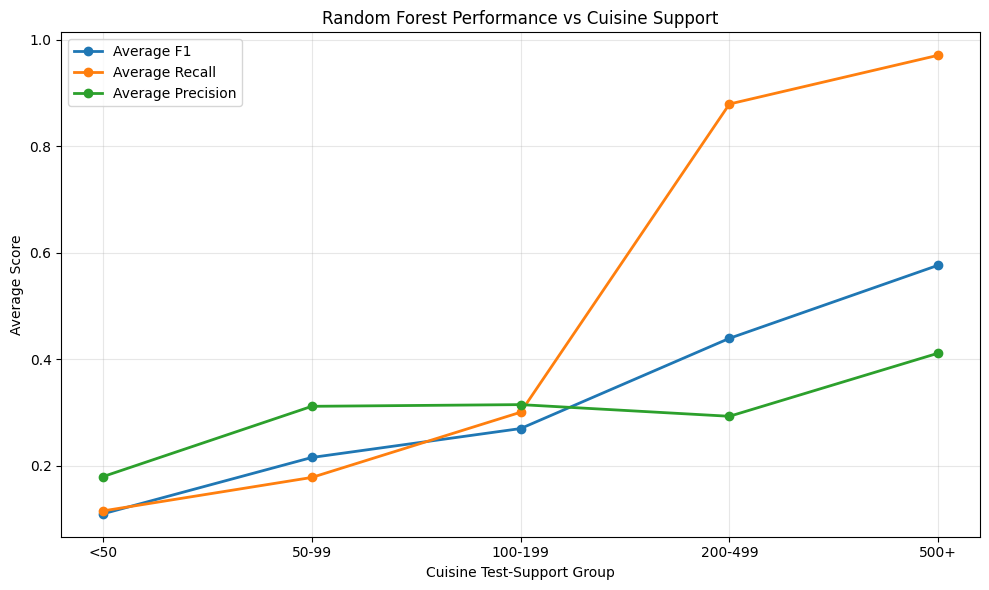

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    support_analysis["Support_Group"],
    support_analysis["Avg_F1"],
    marker="o",
    linewidth=2,
    label="Average F1"
)

plt.plot(
    support_analysis["Support_Group"],
    support_analysis["Avg_Recall"],
    marker="o",
    linewidth=2,
    label="Average Recall"
)

plt.plot(
    support_analysis["Support_Group"],
    support_analysis["Avg_Precision"],
    marker="o",
    linewidth=2,
    label="Average Precision"
)

plt.xlabel("Cuisine Test-Support Group")
plt.ylabel("Average Score")
plt.title("Random Forest Performance vs Cuisine Support")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [46]:
print("📋 COMPLETE SUPPORT VS PERFORMANCE TABLE")
print("=" * 80)

display(
    rf_cuisine_results[
        [
            "Cuisine",
            "Support",
            "Support_Group",
            "Precision",
            "Recall",
            "F1"
        ]
    ].sort_values(
        "Support",
        ascending=False
    ).style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "Support": "{:.0f}"
    })
)

📋 COMPLETE SUPPORT VS PERFORMANCE TABLE


,Cuisine,Support,Support_Group,Precision,Recall,F1
0,North Indian,792,500+,0.4649,0.9962,0.6340
2,Chinese,547,500+,0.3573,0.9452,0.5186
6,Fast Food,397,200-499,0.2925,0.8791,0.4390
9,Mughlai,199,100-199,0.2980,0.3668,0.3288
7,Italian,153,100-199,0.3180,0.5425,0.4010
25,Bakery,149,100-199,0.1837,0.0604,0.0909
5,Continental,147,100-199,0.3333,0.6531,0.4414
8,Cafe,141,100-199,0.4615,0.3404,0.3918
19,Desserts,131,100-199,0.3548,0.0840,0.1358
28,South Indian,127,100-199,0.2500,0.0236,0.0432


In [47]:
# Correlation between test support and F1
pearson_corr = rf_cuisine_results["Support"].corr(
    rf_cuisine_results["F1"],
    method="pearson"
)

spearman_corr = rf_cuisine_results["Support"].corr(
    rf_cuisine_results["F1"],
    method="spearman"
)

print("📈 SUPPORT vs F1 CORRELATION")
print("=" * 50)
print(f"Pearson correlation  : {pearson_corr:.4f}")
print(f"Spearman correlation : {spearman_corr:.4f}")

📈 SUPPORT vs F1 CORRELATION
Pearson correlation  : 0.5951
Spearman correlation : 0.4600


### 6.4 Final Model Comparison


In [48]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# FINAL MODEL COMPARISON
# ============================================================

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Micro Precision": [
        test_precision,
        rf_precision
    ],
    "Micro Recall": [
        test_recall,
        rf_recall
    ],
    "Micro F1": [
        test_micro_f1,
        rf_micro_f1
    ],
    "Macro F1": [
        test_macro_f1,
        rf_macro_f1
    ],
    "Weighted F1": [
        test_weighted_f1,
        rf_weighted_f1
    ],
    "Hamming Loss": [
        test_hamming,
        rf_hamming
    ],
    "Exact Match": [
        test_exact_match,
        rf_exact_match
    ]
})

print("📊 FINAL MODEL COMPARISON")
print("=" * 80)

display(
    model_comparison.style.format({
        "Micro Precision": "{:.4f}",
        "Micro Recall": "{:.4f}",
        "Micro F1": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}",
        "Hamming Loss": "{:.4f}",
        "Exact Match": "{:.4f}"
    })
)


📊 FINAL MODEL COMPARISON


,Model,Micro Precision,Micro Recall,Micro F1,Macro F1,Weighted F1,Hamming Loss,Exact Match
0,Logistic Regression,0.3500,0.5200,0.4184,0.1569,0.3378,0.0651,0.0348
1,Random Forest,0.3629,0.5591,0.4401,0.1753,0.3680,0.0640,0.0310


In [49]:
from IPython.display import display, Markdown

# Dynamic comparative summary — always reflects the latest clean Run All.
comparison_md = f"""### Final Comparative Summary

| Model | Validation Micro F1 | Test Micro F1 | Test Macro F1 | Test Weighted F1 | Test Hamming Loss |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | **{best_log_val_f1:.4f}** | {test_micro_f1:.4f} | {test_macro_f1:.4f} | {test_weighted_f1:.4f} | {test_hamming:.4f} |
| Random Forest | **{rf_best_val_f1:.4f}** | **{rf_micro_f1:.4f}** | **{rf_macro_f1:.4f}** | **{rf_weighted_f1:.4f}** | **{rf_hamming:.4f}** |

Random Forest was selected using the validation Micro F1 (**{rf_best_val_f1:.4f} vs {best_log_val_f1:.4f}**) and then evaluated on the frozen test set, where it achieved a Micro F1 of **{rf_micro_f1:.4f}**.
"""
display(Markdown(comparison_md))


### Final Comparative Summary

| Model | Validation Micro F1 | Test Micro F1 | Test Macro F1 | Test Weighted F1 | Test Hamming Loss |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | **0.4235** | 0.4184 | 0.1569 | 0.3378 | 0.0651 |
| Random Forest | **0.4398** | **0.4401** | **0.1753** | **0.3680** | **0.0640** |

Random Forest was selected using the validation Micro F1 (**0.4398 vs 0.4235**) and then evaluated on the frozen test set, where it achieved a Micro F1 of **0.4401**.


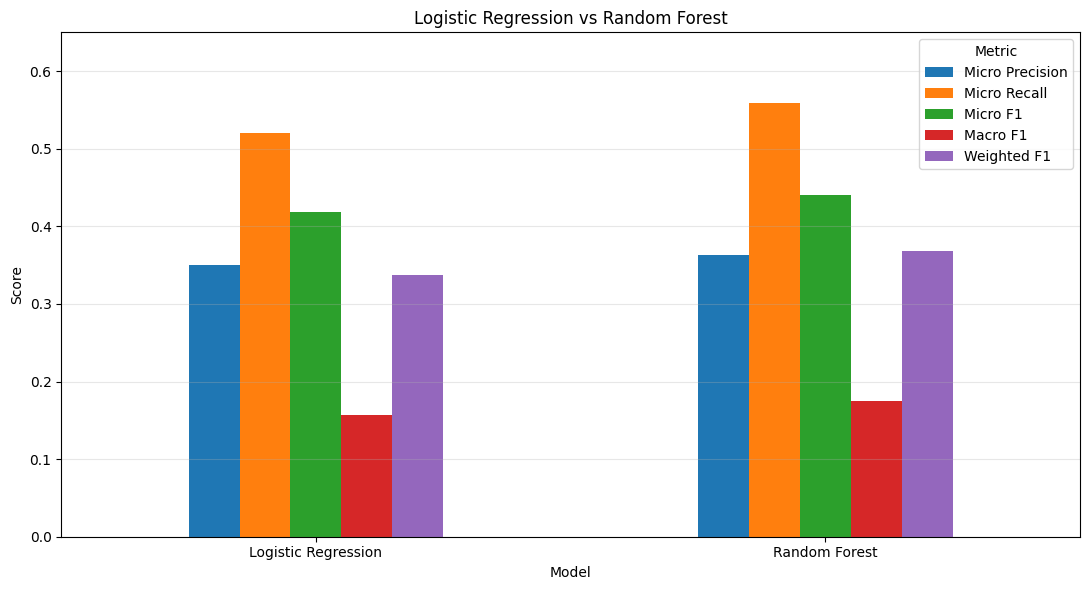

In [50]:
metrics_to_plot = [
    "Micro Precision",
    "Micro Recall",
    "Micro F1",
    "Macro F1",
    "Weighted F1"
]

plot_df = model_comparison.set_index("Model")[metrics_to_plot]

ax = plot_df.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Logistic Regression vs Random Forest")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 0.65)
plt.legend(title="Metric")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 6.5 Cuisine Performance Visualizations


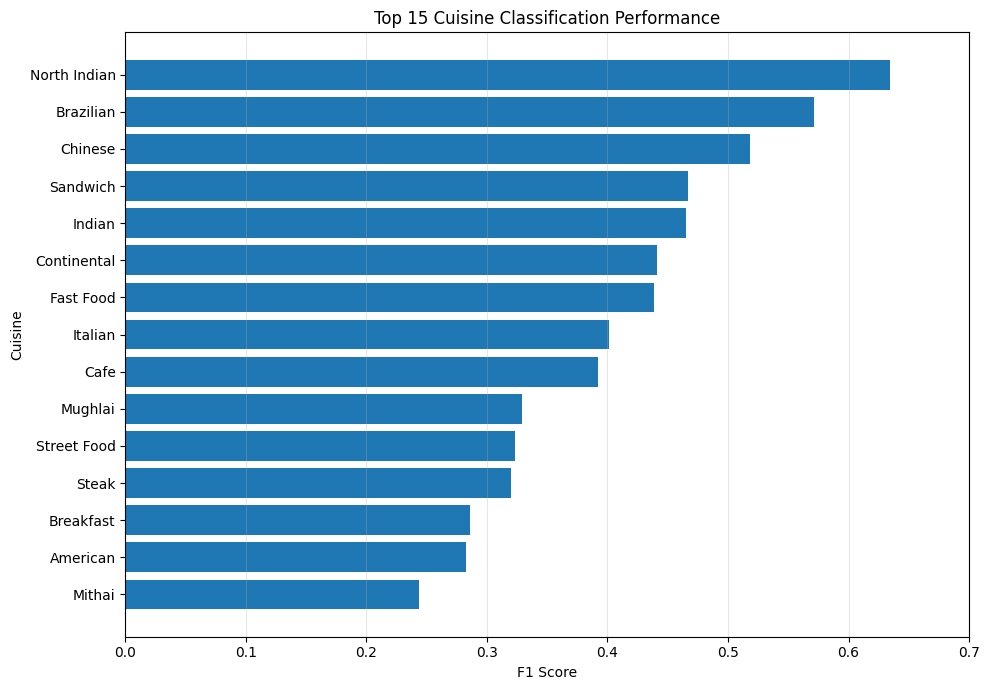

In [51]:
import matplotlib.pyplot as plt

top_cuisines = (
    rf_cuisine_results
    .sort_values("F1", ascending=False)
    .head(15)
    .sort_values("F1")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_cuisines["Cuisine"],
    top_cuisines["F1"]
)

plt.xlabel("F1 Score")
plt.ylabel("Cuisine")
plt.title("Top 15 Cuisine Classification Performance")
plt.xlim(0, 0.7)
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

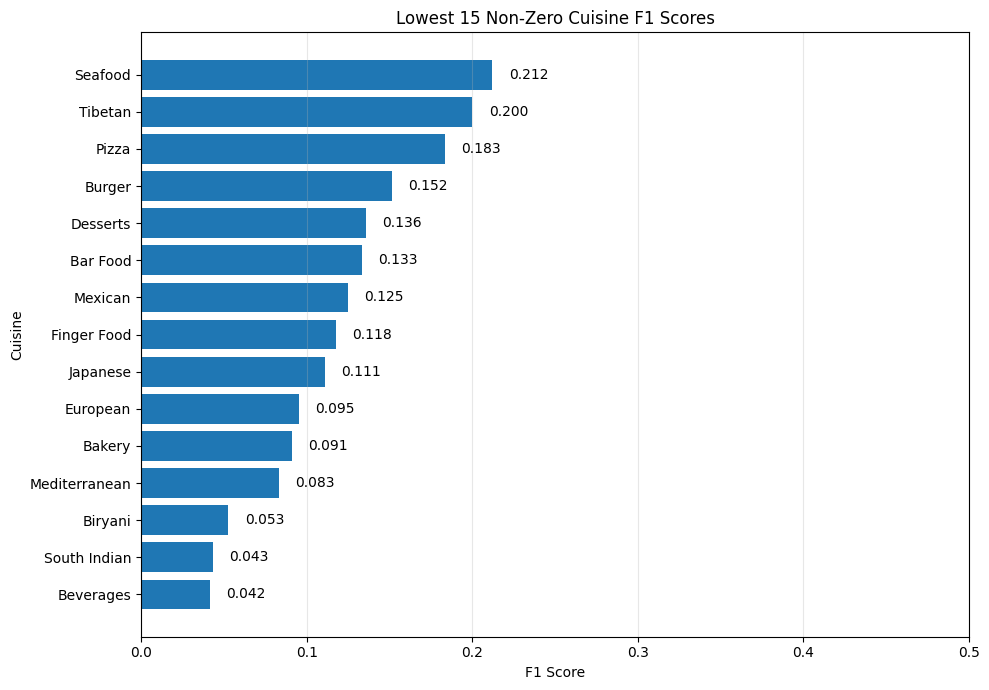

In [52]:
import matplotlib.pyplot as plt

# Select cuisines with non-zero F1
nonzero_cuisines = rf_cuisine_results[
    rf_cuisine_results["F1"] > 0
]

# Bottom 15 among non-zero F1 cuisines
bottom_nonzero = (
    nonzero_cuisines
    .sort_values("F1", ascending=True)
    .head(15)
)

plt.figure(figsize=(10, 7))

bars = plt.barh(
    bottom_nonzero["Cuisine"],
    bottom_nonzero["F1"]
)

plt.xlabel("F1 Score")
plt.ylabel("Cuisine")
plt.title("Lowest 15 Non-Zero Cuisine F1 Scores")
plt.xlim(0, 0.5)
plt.grid(axis="x", alpha=0.3)

# Add values to bars
for bar, value in zip(bars, bottom_nonzero["F1"]):
    plt.text(
        value + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center"
    )

plt.tight_layout()
plt.show()

In [53]:
zero_f1 = rf_cuisine_results[
    rf_cuisine_results["F1"] == 0
][["Cuisine", "Support"]]

print("⚠️ CUISINES WITH ZERO F1")
print("=" * 50)

display(zero_f1)

⚠️ CUISINES WITH ZERO F1


,Cuisine,Support
30,Raw Meats,23
31,Salad,19
32,Ice Cream,45
33,Asian,47
34,Thai,47
35,Healthy Food,30
36,Sushi,15
37,Tea,10
38,Lebanese,14
39,Juices,6


In [54]:
# Count how many cuisines were predicted at least once
predicted_counts = Y_test_rf_pred.sum(axis=0)

coverage = (predicted_counts > 0).sum()
total_cuisines = Y_test_rf_pred.shape[1]

print("📊 CUISINE LABEL COVERAGE")
print("=" * 50)
print(f"Total cuisine labels       : {total_cuisines}")
print(f"Cuisines predicted at least once : {coverage}")
print(f"Cuisines never predicted   : {total_cuisines - coverage}")
print(f"Coverage                   : {coverage / total_cuisines:.2%}")

📊 CUISINE LABEL COVERAGE
Total cuisine labels       : 45
Cuisines predicted at least once : 37
Cuisines never predicted   : 8
Coverage                   : 82.22%


### Future Modeling Extension — Label Dependencies

The current Random Forest uses One-vs-Rest, so each cuisine label is modeled independently. Because cuisines can co-occur, a future experiment could evaluate **ClassifierChain** or another multi-label method that explicitly uses label dependencies. This is a proposed extension and is not part of the reported final test results.


In [55]:
from IPython.display import display, Markdown

zero_f1_count = int((rf_cuisine_results["F1"] == 0).sum())
coverage_count = int((predicted_counts > 0).sum())
total_label_count = int(Y_test_rf_pred.shape[1])
coverage_pct = coverage_count / total_label_count

conclusion_md = f"""## 7. Key Findings, Limitations and Conclusion

### Final Model

The One-vs-Rest Random Forest was selected based on validation performance and its validation-selected threshold. Its validation Micro F1 was **{rf_best_val_f1:.4f}**, compared with **{best_log_val_f1:.4f}** for Logistic Regression. The frozen test set was then used only for final held-out evaluation.

The primary model uses **{len(primary_features)} structured features** after excluding redundant `Currency` information.

On the frozen test set, Random Forest achieved:

- Micro Precision: **{rf_precision:.4f}**
- Micro Recall: **{rf_recall:.4f}**
- Micro F1: **{rf_micro_f1:.4f}**
- Macro F1: **{rf_macro_f1:.4f}**
- Weighted F1: **{rf_weighted_f1:.4f}**
- Hamming Loss: **{rf_hamming:.4f}**
- Exact Match: **{rf_exact_match:.4f}**
- Cuisine label coverage: **{coverage_pct:.2%} ({coverage_count} of {total_label_count} labels)**

### Why Performance Is Limited

Cuisine prediction is difficult because the task is multi-label and the available structured features do not directly describe cuisine identity. Restaurant Name was excluded from the primary model to reduce the risk of high-cardinality memorization and leakage, so the model relies mainly on location, pricing, ratings, votes, and restaurant-service attributes.

The difference between Micro F1 (**{rf_micro_f1:.4f}**) and Macro F1 (**{rf_macro_f1:.4f}**) also shows that performance is uneven across cuisine labels. Exact Match is only **{rf_exact_match:.2%}**, reflecting the difficulty of predicting the complete set of cuisines for a restaurant.

### Long-Tail and Imbalance Analysis

The cuisine distribution is highly imbalanced. The Random Forest produced **zero F1 for {zero_f1_count} of the {total_label_count} supported cuisines** on the test set.

The relationship between test support and F1 was:

- Pearson correlation: **{pearson_corr:.4f}**
- Spearman correlation: **{spearman_corr:.4f}**

These moderate positive associations indicate that higher-support cuisines generally tended to have higher F1, but support does not fully determine performance. Some rare cuisines achieved relatively high F1, while other classes with more examples received zero F1. Metrics for very small classes should therefore be interpreted cautiously.

### Limitations

- The primary model excludes Restaurant Name and therefore does not use potentially informative textual cuisine signals.
- The cuisine taxonomy is long-tailed, making reliable learning difficult for rare labels.
- The current system uses a common decision threshold across all cuisine labels; class-specific thresholds could potentially improve per-label performance.
- The primary experiment focuses on 45 cuisines with sufficient training support; rarer labels were excluded from the main target matrix.

### Next Steps

1. Test TF-IDF or transformer-based text features from Restaurant Name, with careful leakage and generalization checks.
2. Explore class-specific probability thresholds.
3. Investigate class-aware or resampling strategies for long-tail labels.
4. Evaluate boosting-based multi-label approaches such as XGBoost.
5. Add suitable restaurant text fields if available.
6. Collect or use more balanced training data for rare cuisines.

### Conclusion

The project demonstrates a complete multi-label cuisine classification workflow, including data auditing, feature preprocessing, stratified splitting, baseline modeling, threshold optimization, Random Forest modeling, per-cuisine evaluation, and imbalance analysis. The final Random Forest model was selected from validation results and then evaluated once on the frozen test set. It provides a measurable baseline while clearly exposing the main limitation of the dataset: uneven representation across cuisine categories.
"""
display(Markdown(conclusion_md))


## 7. Key Findings, Limitations and Conclusion

### Final Model

The One-vs-Rest Random Forest was selected based on validation performance and its validation-selected threshold. Its validation Micro F1 was **0.4398**, compared with **0.4235** for Logistic Regression. The frozen test set was then used only for final held-out evaluation.

The primary model uses **11 structured features** after excluding redundant `Currency` information.

On the frozen test set, Random Forest achieved:

- Micro Precision: **0.3629**
- Micro Recall: **0.5591**
- Micro F1: **0.4401**
- Macro F1: **0.1753**
- Weighted F1: **0.3680**
- Hamming Loss: **0.0640**
- Exact Match: **0.0310**
- Cuisine label coverage: **82.22% (37 of 45 labels)**

### Why Performance Is Limited

Cuisine prediction is difficult because the task is multi-label and the available structured features do not directly describe cuisine identity. Restaurant Name was excluded from the primary model to reduce the risk of high-cardinality memorization and leakage, so the model relies mainly on location, pricing, ratings, votes, and restaurant-service attributes.

The difference between Micro F1 (**0.4401**) and Macro F1 (**0.1753**) also shows that performance is uneven across cuisine labels. Exact Match is only **3.10%**, reflecting the difficulty of predicting the complete set of cuisines for a restaurant.

### Long-Tail and Imbalance Analysis

The cuisine distribution is highly imbalanced. The Random Forest produced **zero F1 for 15 of the 45 supported cuisines** on the test set.

The relationship between test support and F1 was:

- Pearson correlation: **0.5951**
- Spearman correlation: **0.4600**

These moderate positive associations indicate that higher-support cuisines generally tended to have higher F1, but support does not fully determine performance. Some rare cuisines achieved relatively high F1, while other classes with more examples received zero F1. Metrics for very small classes should therefore be interpreted cautiously.

### Limitations

- The primary model excludes Restaurant Name and therefore does not use potentially informative textual cuisine signals.
- The cuisine taxonomy is long-tailed, making reliable learning difficult for rare labels.
- The current system uses a common decision threshold across all cuisine labels; class-specific thresholds could potentially improve per-label performance.
- The primary experiment focuses on 45 cuisines with sufficient training support; rarer labels were excluded from the main target matrix.

### Next Steps

1. Test TF-IDF or transformer-based text features from Restaurant Name, with careful leakage and generalization checks.
2. Explore class-specific probability thresholds.
3. Investigate class-aware or resampling strategies for long-tail labels.
4. Evaluate boosting-based multi-label approaches such as XGBoost.
5. Add suitable restaurant text fields if available.
6. Collect or use more balanced training data for rare cuisines.

### Conclusion

The project demonstrates a complete multi-label cuisine classification workflow, including data auditing, feature preprocessing, stratified splitting, baseline modeling, threshold optimization, Random Forest modeling, per-cuisine evaluation, and imbalance analysis. The final Random Forest model was selected from validation results and then evaluated once on the frozen test set. It provides a measurable baseline while clearly exposing the main limitation of the dataset: uneven representation across cuisine categories.
